# Unified model and thixotropy test for GP1 and GP5: Table 6, Fig. 9

The linear (SAOS, Table 3) and nonlinear (LAOS, Tables 4–5) coefficients are joined through the
age-dependent critical stress of eq. (8),

$$\sigma_{cr}(t) = \alpha\left(1 - e^{-(t + t_{rest})/\beta}\right),\qquad t_{rest} = 300\ \mathrm{s},$$

giving the piecewise model of eq. (9). Each coefficient is first fitted as a smooth function of sample
age, then eq. (9) is integrated through the thixotropy protocol (oscillation at 10 rad/s in the linear
range / 30 s at 100 s⁻¹ / oscillation / 100 s⁻¹) and compared with the measurements.

* **Inputs:** `results/coefficients/*.csv`, `results/critical_points.csv` (from `00_amplitude_sweeps`),
  `data/GP1_SAOS_time_sweep.xlsx`, `data/GP*_LAOS_*.xlsx` (sample ages), `data/GP1_3ITT.xlsx`, `data/GP5_3ITT.xlsx`
* **Outputs:** `results/thixotropy/eq8_parameters.csv` (Table 6), `results/thixotropy/GP*_age_fits.csv`,
  `figures/fig09_3ITT_GP1_GP5.png`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

from rhinn_sindy import data, thixotropy as th
from rhinn_sindy.coefficients import load_laos_coefficients, load_saos_coefficients
from rhinn_sindy.paths import RESULTS_DIR
from rhinn_sindy.plotting import COLOR_GP1, COLOR_GP5, save_figure, set_paper_style

set_paper_style()
OUT_DIR = RESULTS_DIR / "thixotropy"
OUT_DIR.mkdir(parents=True, exist_ok=True)
MATERIALS = ["GP1", "GP5"]
COLORS = {"GP1": COLOR_GP1, "GP5": COLOR_GP5}

## Settings

`REPRODUCE_PAPER = True` repeats the analysis exactly as it was done for Fig. 9, including three
choices that look unintended; `False` corrects them:

1. the sample ages of the GP5 SAOS coefficients were read from the **GP1** time sweep
   (same row numbers, but GP1 rows are ~3× further apart in time than GP5 rows);
2. the GP5 age curves of $c_4$ ($\sigma\dot\sigma$) and $c_5$ ($\dot\sigma\sigma^2$) are the fit of the
   $c_3$ ($\sigma^2$) data;
3. the switch between the linear and nonlinear branch used $\sigma < \sigma_{cr}$ instead of
   $|\sigma| < \sigma_{cr}$ (eq. 9), so the negative half of each oscillation always stays linear.

The coefficients behind the age fits of Fig. 9 were also not Tables 3–5: SAOS used the unrounded
identified values (`results/coefficients/identified`), and LAOS used the hand-entered lists in
`AGE_FIT_LAOS` below (the reduced fit at the earliest age, with nonzero $c_3$, $c_4$). With
`REPRODUCE_PAPER = False` the fits use Tables 3–5.

In [2]:
REPRODUCE_PAPER = True

# Strain amplitude of the oscillation intervals (linear range of each material).
ITT_GAMMA0 = {"GP1": 5e-4, "GP5": 2e-4}

# Functional form of each coefficient versus sample age, chosen by inspecting the fits.
AGE_FORMS = {
    "GP1": {"c1s": "shifted_power", "c2s": "kww", "c1": "exp_decay", "c2": "exp_decay",
            "c3": "exp_decay", "c4": "exp_decay", "c5": "poly2", "c6": "saturation",
            "c7": "zero"},
    "GP5": {"c1s": "hill", "c2s": "shifted_power", "c1": "hill", "c2": "hill", "c3": "hill",
            "c4": "hill", "c5": "hill", "c6": "zero", "c7": "zero"},
}

# LAOS coefficients used for the age fits of Fig. 9 (one value per LAOS sheet, ascending age).
AGE_FIT_LAOS = {
    "GP1": {"c1": [0.13457927, 0.09, 0.065, 0.046, 0.034, 0.017, 0.02, 0.002, 0.0036],
            "c2": [0.034185391, 0.027, 0.0168, 0.009, 0.004, 0.003, 0.002, 0.0019, 0.001],
            "c3": [-2.2426354e-4, 0, 0, 0, 0, 0, 0, 0, 0],
            "c4": [9.4950199e-5, 0, 0, 0, 0, 0, 0, 0, 0],
            "c5": [1.0602906e-3, 0.00076, 0.0008, 0.0006, 0.0005, 0.0003, 0.0002, 5.42e-5, 0],
            "c6": [0, 0, 0, 0, 0, 0.00012, 1.8e-5, 0.00016, 4e-5],
            "c7": [0] * 9},
    "GP5": {"c1": [0.01287, 0.0127, 0.01156, 0.0042, 0.002, 0.0014, 0.00105, 0.0008, 0.0007],
            "c2": [0.009, 0.009, 0.0068, 0.00104, 0.0009, 0.00087, 0.0009, 0.00072, 0.00072],
            "c3": [4.387e-7, 3.4e-7, 0, 0, 0, 0, 0, 0, 0],
            "c4": [2.916611e-6, 4.064e-6, 0, 0, 0, 0, 0, 0, 0],
            "c5": [1.443e-7, 0, 1.82e-7, 5.8e-7, 2.7e-7, 1.61e-7, 0, 0, 0],
            "c6": [0] * 9, "c7": [0] * 9},
}

## Table 6: parameters of eq. (8)

In [3]:
critical = pd.read_csv(RESULTS_DIR / "critical_points.csv", index_col="material")
table6 = pd.DataFrame(
    [(gp, *th.eq8_parameters(critical.loc[gp, "sigma_cr"], critical.loc[gp, "t_cr"]),
      critical.loc[gp, "sigma_cr"]) for gp in MATERIALS],
    columns=["material", "alpha_Pa", "beta_s", "sigma_cr_Pa"])
table6.to_csv(OUT_DIR / "eq8_parameters.csv", index=False, float_format="%.6g")
table6.round(2)

,material,alpha_Pa,beta_s,sigma_cr_Pa
0,GP1,0.79,717.42,0.5
1,GP5,316.40,587.52,200.0


## Coefficients versus sample age

Every sample age contributes as many points as it has measurements: 500 points over a 1.5 s
window per SAOS row and every cleaned data point of a LAOS sheet. Ages are seconds since the start
of the respective measurement.

In [4]:
def age_fit_data(material):
    saos = load_saos_coefficients(material, "identified" if REPRODUCE_PAPER else "paper")
    sweep = "GP1" if (material == "GP5" and REPRODUCE_PAPER) else material
    t_sweep = data.load_saos_time_sweep(sweep)["Time"].to_numpy(float)
    window = np.linspace(0, 1.5, 500)
    t_saos = np.concatenate([t_sweep[r] - t_sweep[0] + 1e-5 + window for r in saos["row"]])
    out = {"c1s": (t_saos, np.repeat(saos["c1"].to_numpy(), len(window))),
           "c2s": (t_saos, np.repeat(saos["c2"].to_numpy(), len(window)))}

    laos = load_laos_coefficients(material)
    if REPRODUCE_PAPER:
        laos = laos.assign(**AGE_FIT_LAOS[material])
    times = [th.laos_sheet_times(material, s) for s in laos["sheet"]]
    for c in th.LAOS_NAMES:
        out[c] = (np.concatenate(times),
                  np.concatenate([np.full(len(t), v) for t, v in zip(times, laos[c])]))
    if material == "GP5" and REPRODUCE_PAPER:
        out["c4"] = out["c5"] = out["c3"]
    return out


fits, fit_data = {}, {}
for gp in MATERIALS:
    fit_data[gp] = age_fit_data(gp)
    fits[gp] = {k: (form, th.fit_age_curve(form, *fit_data[gp][k]))
                for k, form in AGE_FORMS[gp].items()}
    th.save_age_fits(OUT_DIR / f"{gp}_age_fits.csv", fits[gp])
    display(pd.read_csv(OUT_DIR / f"{gp}_age_fits.csv"))

,coefficient,form,p0,p1,p2,p3
0,c1s,shifted_power,6.147675e-01,4.307016e-01,2.201612e+01,7.078655e-18
1,c2s,kww,6.552948e-03,1.409788e+03,3.450791e-01,2.846303e-20
2,c1,exp_decay,1.438041e-01,1.108484e+04,-6.219075e-03,NaN
3,c2,exp_decay,3.915983e-02,9.681053e+03,-1.827190e-03,NaN
4,c3,exp_decay,-3.838523e-04,7.144177e+02,1.635682e-07,NaN
5,c4,exp_decay,1.623317e-04,7.159588e+02,-7.005314e-08,NaN
6,c5,poly2,1.690993e-13,-4.078681e-08,1.035340e-03,NaN
7,c6,saturation,-6.027634e-06,8.837607e-05,1.662490e+04,5.000000e+00
8,c7,zero,NaN,NaN,NaN,NaN


,coefficient,form,p0,p1,p2,p3
0,c1s,hill,1.688905e-04,222.595352,2.837068,3.484411e-07
1,c2s,shifted_power,2.083412e+00,1.835585,166.962556,2.518038e-06
2,c1,hill,1.242814e-02,1396.537353,5.000000,6.797357e-04
3,c2,hill,8.675017e-03,1191.607792,5.000000,5.335365e-04
4,c3,hill,4.458737e-07,659.144721,5.000000,2.023583e-17
5,c4,hill,4.458737e-07,659.144721,5.000000,2.023583e-17
6,c5,hill,4.458737e-07,659.144721,5.000000,2.023583e-17
7,c6,zero,NaN,NaN,NaN,NaN
8,c7,zero,NaN,NaN,NaN,NaN


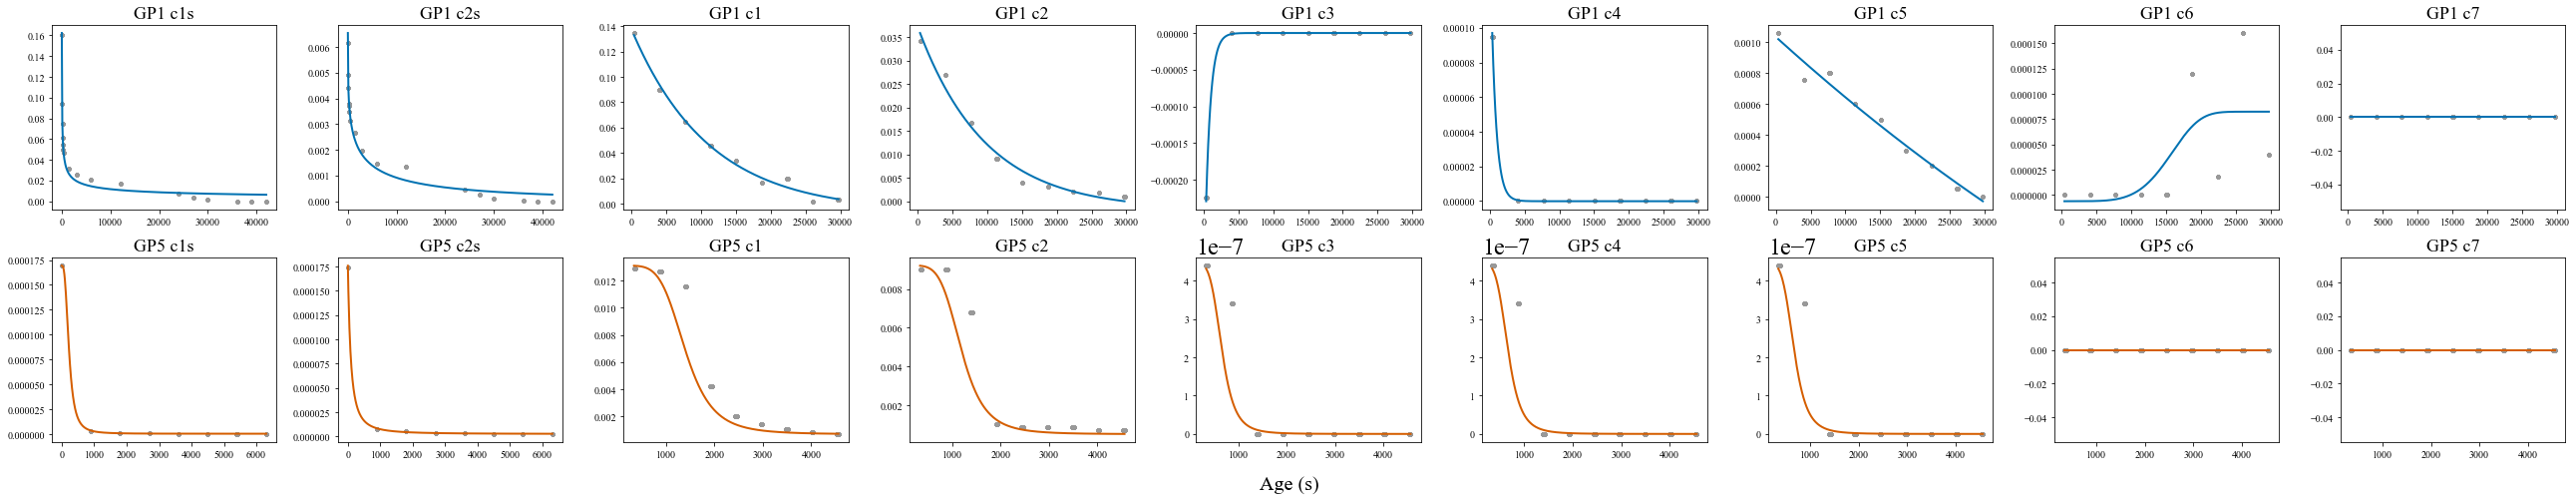

In [5]:
fig, axes = plt.subplots(2, 9, figsize=(36, 7))
for row, gp in enumerate(MATERIALS):
    for ax, k in zip(axes[row], AGE_FORMS[gp]):
        t, y = fit_data[gp][k]
        tt = np.linspace(t.min(), t.max(), 400)
        ax.plot(t, y, "o", color="0.6", ms=3)
        ax.plot(tt, th.evaluate_age_fits({k: fits[gp][k]}, tt)[k], color=COLORS[gp], lw=2)
        ax.set_title(f"{gp} {k}", fontsize=18)
        ax.tick_params(labelsize=10)
fig.supxlabel("Age (s)", fontsize=20)
fig.tight_layout()
plt.show()

## Thixotropy protocol: model vs. experiment (Fig. 9)

In [6]:
results, measured = {}, {}
for gp in MATERIALS:
    results[gp] = th.simulate_itt(fits[gp], critical.loc[gp, "sigma_cr"], critical.loc[gp, "t_cr"],
                                  gamma0=ITT_GAMMA0[gp], use_abs=not REPRODUCE_PAPER)
    measured[gp] = th.load_itt_data(gp)

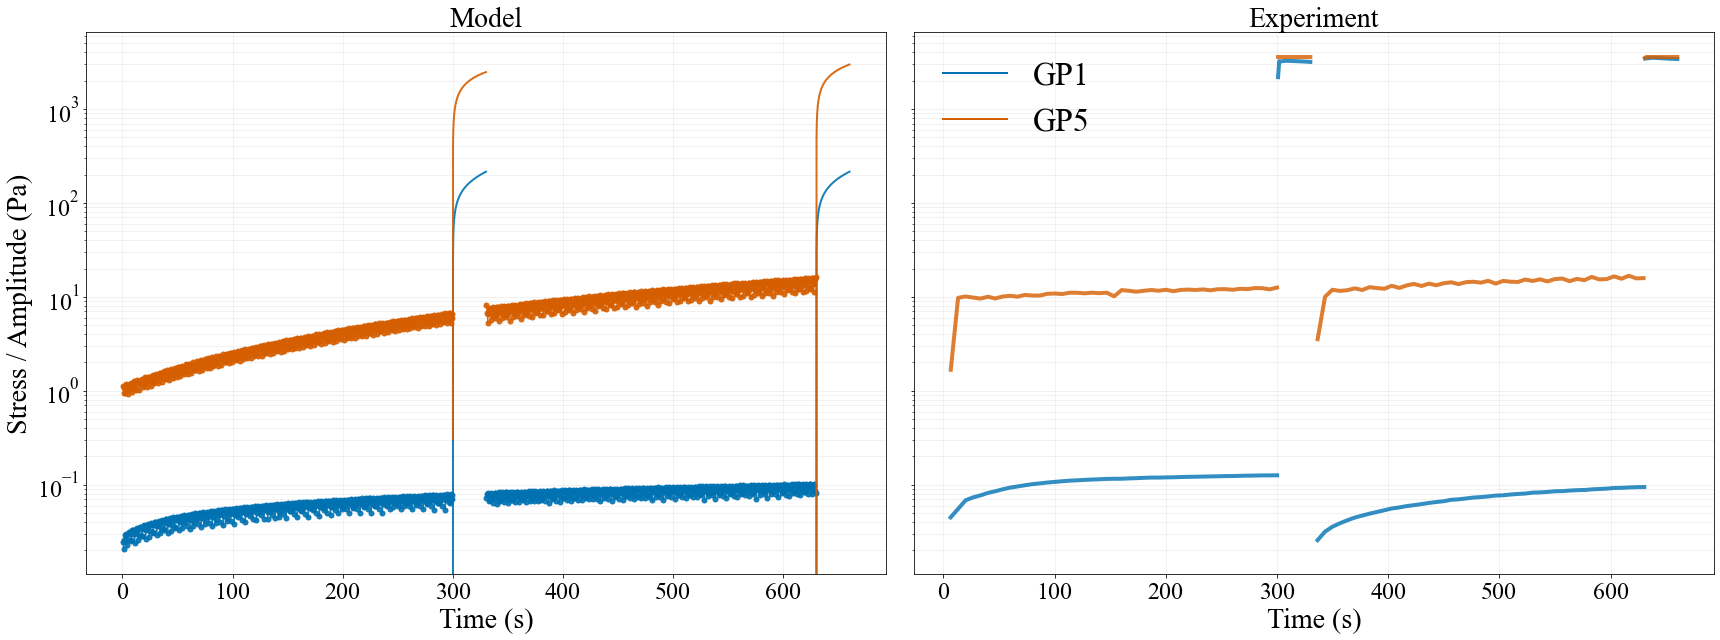

In [7]:
# Left: per-cycle stress amplitude in the oscillation intervals, stress in the steady-shear intervals.
fig, (ax_m, ax_e) = plt.subplots(1, 2, figsize=(24, 9), sharey=True)
for gp in MATERIALS:
    for step, meas in zip(results[gp], measured[gp]):
        if step["mode"] == "oscillatory":
            ax_m.plot(step["cycle_t"], step["cycle_amp"], "o-", color=COLORS[gp], lw=1, alpha=0.9)
        else:
            ax_m.plot(step["t"], step["sigma"], "-", color=COLORS[gp], lw=2, alpha=0.9)
        ax_e.plot(meas["t"], meas["sigma"], color=COLORS[gp], alpha=0.8)

ax_m.set(xlabel="Time (s)", ylabel="Stress / Amplitude (Pa)", yscale="log", title="Model")
ax_e.set(xlabel="Time (s)", yscale="log", title="Experiment")
for ax in (ax_m, ax_e):
    ax.grid(True, which="both", alpha=0.2)
ax_e.legend(handles=[Line2D([0], [0], color=COLORS[gp], lw=2, label=gp) for gp in MATERIALS],
            loc="upper left", frameon=False)
fig.tight_layout(w_pad=2.5)
save_figure(fig, "fig09_3ITT_GP1_GP5.png")
plt.show()